In [ ]:
%reload_ext autoreload
%autoreload 2

In [ ]:
import os

os.environ['CUDA_VISIBLE_DEVICES'] = '2'
os.environ['XLA_PYTHON_CLIENT_MEM_FRACTION'] = '1'

In [ ]:
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from corner import corner, overplot_lines, overplot_points
from jax import jit
from scipy.stats import qmc
from scipy.stats import t as stuent_t
from raddest.reg.func import saturated_linear
from utils.linear_model import get_ODR, get_OLS, xy2logxy


In [ ]:
k = 1.3
b = 0.1
sig = 0.2
N = 10000

x = 10**np.random.normal(0, 0.3, size=N)
x0, x1 = np.percentile(np.log10(x), [5, 95])
c0, c1 = np.percentile(k * np.log10(x) + b, [1, 99])

y = 10**(saturated_linear(np.log10(x), k, b, x0, x1, c0, c1) +
         np.random.normal(0, sig, size=N))

x_err = np.random.uniform(0.1, 0.5, size=N)
x_obs = np.random.normal(x, x_err)

y_err = np.random.uniform(0.1, 0.5, size=N)
y_obs = np.random.normal(y, y_err)

x_err = jnp.asarray(x_err)
x_obs = jnp.asarray(x_obs)
y_err = jnp.asarray(y_err)
y_obs = jnp.asarray(y_obs)

Text(0, 0.5, 'log(y)')

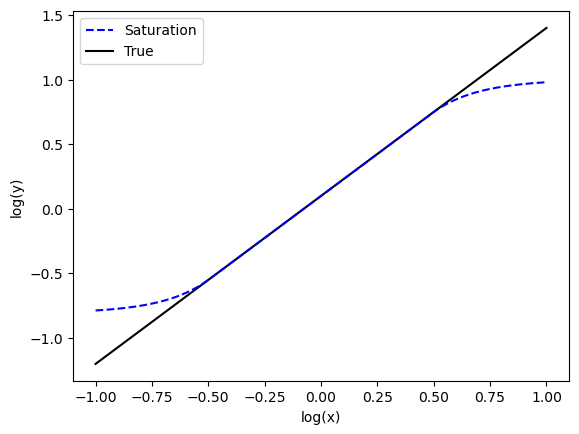

In [ ]:
log_xx = np.linspace(-1, 1, 1000)
log_yy = k * log_xx + b
log_yy_sat = saturated_linear(log_xx, k, b, x0, x1, c0, c1)
plt.plot(log_xx,
         log_yy_sat,
         color='blue',
         label='Saturation',
         zorder=10,
         linestyle='--')
plt.plot(log_xx, log_yy, color='black', label='True')
plt.legend()
plt.xlabel('log(x)')
plt.ylabel('log(y)')

In [ ]:
logx_obs, logy_obs, logx_err, logy_err = xy2logxy(x_obs, y_obs, x_err, y_err)

/work/jingtao/workspace/myrepos/raddest/example/utils/linear_model.py:24: RuntimeWarning: invalid value encountered in log10
  logx = np.log10(x)
/work/jingtao/workspace/myrepos/raddest/example/utils/linear_model.py:25: RuntimeWarning: invalid value encountered in log10
  logy = np.log10(y)


In [ ]:
res_ODR = get_ODR(logx_obs, logy_obs)
res_OLS = get_OLS(logx_obs, logy_obs)

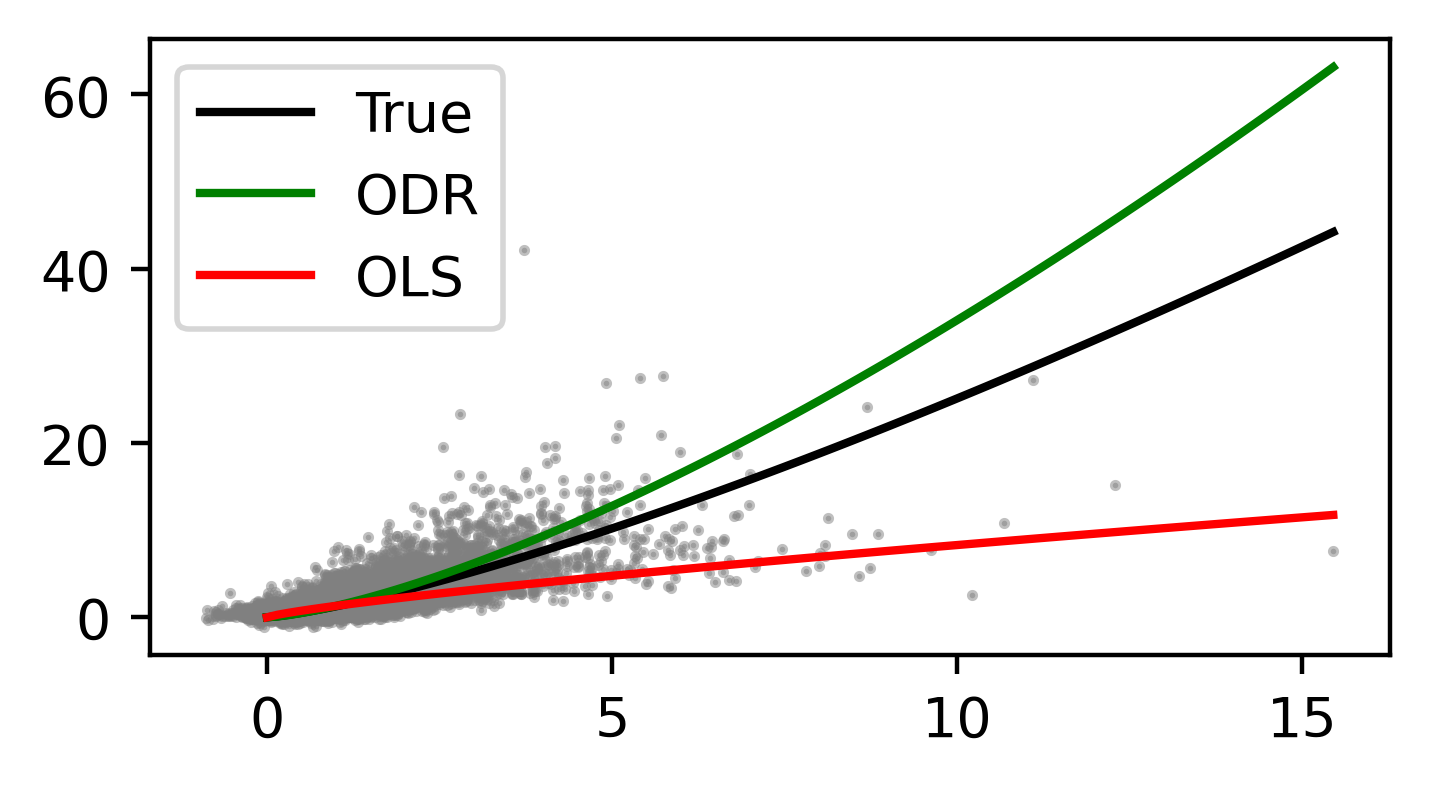

In [ ]:
plt.figure(figsize=(4, 2), dpi=400)

plt.scatter(x_obs, y_obs, s=1, color='gray', alpha=0.5)
xx = np.linspace(max(1e-10, x_obs.min()), x_obs.max(), 100)
yy = 10**(k * np.log10(xx) + b)
# yy_sat = 10**linear_sigmoid(np.log10(xx), k, b, x0, x1, c0, c1)
yy_ODR = 10**res_ODR['func_xy'](np.log10(xx))
yy_OLS = 10**res_OLS['func'](np.log10(xx))

plt.plot(xx, yy, color='black', label='True')
plt.plot(xx, yy_ODR, color='green', label='ODR')
plt.plot(xx, yy_OLS, color='red', label='OLS')

plt.legend()

### Fit p(x, x_err) and p(y, y_err)

In [ ]:
from jax.scipy.stats import norm

from raddest.api.fitter import (LogLinearKS, LogLinearML,
                                LogLinearStudentTML, RegressorML)
from raddest.api.flowvi import FlowVI
from raddest.reg.map import get_w_add_lognorm
from raddest.transfer import NegLogPlus

In [ ]:
xflow = FlowVI(x_min=0,
               x_max=x_obs.max(),
               x_err_min=0,
               x_err_max=x_err.max() * 1.2,
               transfer=NegLogPlus())

xflow.fit(x_obs, x_err, verbose=True)

100%|██████████| 100/100 [00:08<00:00, 12.10it/s]


step 0: loss 0.33286863565444946
step 10: loss 0.30410510301589966
step 20: loss 0.3025490641593933
step 30: loss 0.29894348978996277
step 40: loss 0.2985735833644867
step 50: loss 0.29814472794532776
step 60: loss 0.29535236954689026
step 70: loss 0.29431384801864624


In [ ]:
xflow.ks_test(x_obs, x_err, 10000)

(0.01770002394914627, 0.2595719114302081)

In [ ]:
yflow = FlowVI(x_min=0,
               x_max=y_obs.max(),
               x_err_min=0,
               x_err_max=y_err.max() * 1.2,
               transfer=NegLogPlus())

yflow.fit(y_obs, y_err, verbose=True)

100%|██████████| 100/100 [00:07<00:00, 13.04it/s]


step 0: loss 0.8522070050239563
step 10: loss 0.8329933285713196
step 20: loss 0.8271170854568481
step 30: loss 0.8245213627815247
step 40: loss 0.8225400447845459
step 50: loss 0.8211613297462463
step 60: loss 0.819977343082428


In [ ]:
yflow.ks_test(y_obs, y_err, 10000)

(0.012700021266937256, 0.6700367191298763)

### Normal Model

In [ ]:
regressor_logLinear_ML = LogLinearML(xflow, yflow)

In [ ]:
params_ml, params_std, cov = regressor_logLinear_ML.fit(
    x_obs,
    x_err,
    y_obs,
    y_err,
    [1., 0., 0.1],
    kde_batch_size=None,  # set it to 100000 or less if OOM
    verbose=True)  # loss is log-likelihood/n_samples

0 1.0020348 0.0059381695 0.11536086 -0.020217214
1000 1.1476539 0.10427118 0.20957214 0.5356192
2000 1.1972896 0.099584654 0.20674267 0.53830516
3000 1.2160412 0.09763057 0.20594653 0.5386888
4000 1.2231407 0.0968662 0.20568372 0.5387436
5000 1.2258343 0.096572794 0.20558938 0.5387516
6000 1.2268552 0.096461035 0.20555447 0.53875273
converged, so stop with 6000 iterations


In [ ]:
print('ML fitted:', *params_ml)
print('Truth:', k, b, sig)

ML fitted: 1.2268552 0.096461035 0.20555447
Truth: 1.3 0.1 0.2


### T Model

In [ ]:
loglinear_studentT_ML = LogLinearStudentTML(xflow, yflow)

In [ ]:
params_ml_t, params_std_t, cov_t = loglinear_studentT_ML.fit(
    x_obs,
    x_err,
    y_obs,
    y_err,
    [1., 0., 2., 0.1],
    kde_batch_size=None,  # set it to 100000 or less if OOM
    verbose=True)  # loss is log-likelihood/n_samples

0 1.0005355 0.0019894883 1.9999673 0.102559604 0.31575987
1000 1.1675197 0.11031935 2.0292158 0.13199936 0.5000545
2000 1.2187957 0.104580946 2.0565755 0.1304509 0.5037359
3000 1.2358496 0.102494515 2.082804 0.13058612 0.5047476
4000 1.2415862 0.10173334 2.108185 0.1310848 0.5054287
5000 1.2434726 0.10143775 2.1328268 0.13166952 0.5060398
6000 1.2440335 0.101305544 2.1567943 0.13226408 0.506616
7000 1.2441363 0.10123184 2.1801367 0.13284604 0.50716037
8000 1.244081 0.101179175 2.2028787 0.13340844 0.50767773
9000 1.2439618 0.10113723 2.2250667 0.13395107 0.5081708


In [ ]:
print('ML fitted:', *params_ml_t)
print('Truth:', k, b, sig)

ML fitted: 1.2438427 0.10109746 2.246712 0.1344723
Truth: 1.3 0.1 0.2


In [ ]:
q_16, q_84 = stuent_t.ppf([0.16, 0.84],
                          float(params_ml_t[-2]),
                          scale=float(params_ml_t[-1]))
(q_84 - q_16) / 2

0.17065236199792166

### KS

In [ ]:
logLinear_KS = LogLinearKS(xflow, yflow)

In [ ]:
params_mean, params_std, res_arr = logLinear_KS.fit(
    x_obs,
    y_obs,
    params_list=[
        np.linspace(0.5, 1.5, 7),
        np.linspace(-0.1, 0.3, 7),
        np.linspace(0.1, 0.3, 5)
    ],
    verbose=True)
print(params_mean, params_std)

----
k: 1.262 +/- 0.116
b: 0.098 +/- 0.013
sig: 0.184 +/- 0.058
----
k: 1.298 +/- 0.114
b: 0.089 +/- 0.023
sig: 0.192 +/- 0.068
----
k: 1.299 +/- 0.114
b: 0.096 +/- 0.022
sig: 0.189 +/- 0.074
----
k: 1.311 +/- 0.105
b: 0.090 +/- 0.022
sig: 0.190 +/- 0.067
----
k: 1.283 +/- 0.104
b: 0.095 +/- 0.023
sig: 0.196 +/- 0.073
----
k: 1.299 +/- 0.106
b: 0.089 +/- 0.023
sig: 0.191 +/- 0.073
----
k: 1.288 +/- 0.099
b: 0.096 +/- 0.022
sig: 0.195 +/- 0.068
----
k: 1.285 +/- 0.099
b: 0.089 +/- 0.023
sig: 0.204 +/- 0.066
----
k: 1.295 +/- 0.098
b: 0.094 +/- 0.024
sig: 0.192 +/- 0.073
----
k: 1.301 +/- 0.100
b: 0.090 +/- 0.023
sig: 0.192 +/- 0.073
----
k: 1.310 +/- 0.105
b: 0.092 +/- 0.023
sig: 0.193 +/- 0.072
max iteration reached
[1.30701207 0.09064227 0.19298591] [0.10021183 0.0201901  0.07029305]


### Saturated Log-Linear ML (customized)

In [ ]:
from raddest.reg.func import saturated_linear_smooth
from raddest.reg.func_jax import saturated_linear_smooth_jax

In [ ]:
def saturated_loglinear_scatter(x, params):
    params_loglinear = params[:-1]
    sig = params[-1]
    log10_y_pred = saturated_linear_smooth(np.log10(x),
                                           *params_loglinear,
                                           width=0.01)
    return np.power(10,
                    log10_y_pred + np.random.normal(scale=sig, size=x.shape))


@jit
def saturated_loglinear_jax(x, params):
    '''
    params: (k, b, x0, x1, c0, c1)
    '''
    log10_y_pred = saturated_linear_smooth_jax(jnp.log10(jnp.abs(x)),
                                               *params,
                                               width=0.1)
    return log10_y_pred


@jit
def lognorm(x, y, params):
    return jnp.where((x < 0) | (y < 0), 0,
                     norm.pdf(jnp.log10(jnp.abs(y)),
                              loc=saturated_loglinear_jax(x, params[:-1]),
                              scale=params[-1]))


def construct_saturated_linear_step(d_log_likelihood):

    @jit
    def step(params, x_ext, y_ext, w, lr=1e-3):
        dparams = d_log_likelihood(params, x_ext, y_ext, w)[0]
        k, b, x0, x1, c0, c1, sig = params
        dk, db, dx0, dx1, dc0, dc1, dsig = dparams

        k = jnp.clip(k + lr * dk, -1e2, 1e2)
        b = jnp.clip(b + lr * db, -1e2, 1e2)
        x0 = jnp.clip(x0 + lr * dx0, -1e2, 1e2)
        x1 = jnp.clip(x1 + lr * dx1, -1e2, 1e2)
        c0 = jnp.clip(c0 + lr * dc0, -1e2, 1e2)
        c1 = jnp.clip(c1 + lr * dc1, -1e2, 1e2)

        sig = jnp.clip(sig + lr * dsig, 1e-2, 1e2)
        return (k, b, x0, x1, c0, c1, sig)

    return step


def log_prior(params):
    return jnp.where(params[-1] <= 0, -jnp.inf, 0)


saturated_loglinear_regressor_c = RegressorML(
    xflow,
    yflow,
    p_cond=lognorm,
    step_constructor=construct_saturated_linear_step,
    get_w_add=get_w_add_lognorm,
    func_x2y=saturated_loglinear_scatter,
    log_prior=log_prior)

In [ ]:
params_ml_saturated_c, params_std_saturated_c, cov_saturated_c = saturated_loglinear_regressor_c.fit(
    x_obs,
    x_err,
    y_obs,
    y_err,
    [
        1., 0.,
        np.log10(np.percentile(x_obs, 5)),
        np.log10(np.percentile(x_obs, 95)), -1.,
        np.log10(np.percentile(y_obs, 99)), 0.1
    ],
    kde_batch_size=None,  # set it to 100000 or less if OOM
    verbose=True)

0 0.6107337 0.38346553 -0.5286081 0.50545967 -1.3864741 1.0384371 0.11369187 -0.81042
1000 0.9600777 0.122141376 -0.527708 0.51493055 -1.3866065 1.0428238 0.22764732 0.48649785
2000 1.1190686 0.1171249 -0.51706976 0.51721066 -1.3855073 1.0477624 0.20981161 0.51378936
3000 1.185827 0.11366886 -0.50115585 0.51252687 -1.3836349 1.0496366 0.20488952 0.51885146
4000 1.213988 0.11201012 -0.48190662 0.5055736 -1.3811936 1.0492582 0.2031942 0.52012235
5000 1.2266037 0.111178406 -0.4597973 0.49844897 -1.3782347 1.0478435 0.20243156 0.5208413
6000 1.2330878 0.11068427 -0.4348965 0.49187422 -1.3747419 1.0460593 0.20197628 0.52156425
7000 1.2373512 0.110297 -0.4072295 0.48604977 -1.370653 1.0441519 0.20162086 0.5224033
8000 1.2410835 0.109888256 -0.37695354 0.48094794 -1.3659045 1.0422971 0.20129058 0.5233868
9000 1.2450798 0.10937592 -0.34448245 0.4764456 -1.3604381 1.040509 0.20096193 0.5245112
10000 1.2497048 0.108703114 -0.31055605 0.47238675 -1.3542331 1.0388231 0.20064119 0.5257423
11000 1.2

In [ ]:
print(params_ml_saturated_c)
print(k, b, x0, x1, c0, c1, sig)

[ 1.3467946   0.04488171 -0.2182205   0.39153123 -0.41956344  1.1374289
  0.19501762]
1.3 0.1 -0.4877620825166232 0.49845004660512354 -0.8176626194290961 1.0218297470215614 0.2


### Saturated Log-Linear ML (built-in)

In [ ]:
from raddest.api.fitter import SaturatedLogLinearML

In [ ]:
saturated_loglinear = SaturatedLogLinearML(xflow, yflow)

In [ ]:
params0 = [
    1., 0., -0.5,
    np.log10(np.percentile(x_obs, 95)), -1.,
    np.log10(np.percentile(y_obs, 99)), 0.1
]
# params0 = [k, b, x0, x1, c0, c1, sig]

params_ml_saturated, params_std_saturated, cov_saturated = saturated_loglinear.fit(
    x_obs,
    x_err,
    y_obs,
    y_err,
    params0,
    ignore_y_err_c_y=True,
    kde_batch_size=None,  # set it to 100000 or less if OOM
    verbose=True)

0 1.0019776 0.0061313673 -0.4999897 0.49942753 -0.9999884 1.0431815 0.115681484 -1.0369807
1000 1.1651886 0.11438857 -0.4990617 0.50349987 -1.001496 1.0483766 0.20802103 -0.44903758
2000 1.2312106 0.109577656 -0.49707413 0.50004417 -1.0028268 1.0496953 0.20475507 -0.44439188
3000 1.2612507 0.107083336 -0.49468818 0.49380398 -1.0035632 1.0495522 0.20374922 -0.4433926
4000 1.2754366 0.10575661 -0.4922105 0.48682246 -1.003916 1.0488105 0.203342 -0.4431251
5000 1.2824904 0.105014235 -0.4897071 0.48004353 -1.004065 1.0478592 0.2031323 -0.4430198
6000 1.286268 0.104572244 -0.48718724 0.47385284 -1.0040772 1.0469055 0.20300409 -0.44295928
7000 1.2884983 0.10429384 -0.48465404 0.4683694 -1.0040457 1.0459617 0.20291586 -0.44291663
8000 1.2899683 0.10410301 -0.4820929 0.46359074 -1.0039265 1.0451273 0.20285021 -0.44288427
9000 1.2910348 0.10396506 -0.47951308 0.45946354 -1.0038073 1.0444005 0.20279916 -0.44285893
10000 1.2918735 0.10385917 -0.47691184 0.4559174 -1.0036881 1.0437787 0.20275754 -0

In [ ]:
saturated_loglinear.ks_test(params_ml_saturated, x_obs, y_obs)

(0.012500009499490261, 0.6085545284980353)

In [ ]:
initial_state = np.random.uniform(
    low=params_ml_saturated - 3 * params_std_saturated,
    high=params_ml_saturated + 3 * params_std_saturated,
    size=(14, 7))

In [ ]:
sampler = saturated_loglinear.get_posterior_mcmc(
    x_obs,
    x_err,
    y_obs,
    y_err,
    ndim=7,
    nsteps=30000,
    initial_state=initial_state,
    ignore_y_err_c_y=True,
    run_mcmc_kwargs={'progress': True})

  0%|          | 0/30000 [00:00<?, ?it/s]/home/jingtao/software/anaconda3/envs/jax/lib/python3.9/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
 37%|███▋      | 11088/30000 [00:51<01:27, 214.99it/s]/home/jingtao/software/anaconda3/envs/jax/lib/python3.9/site-packages/jax/_src/interpreters/xla.py:154: RuntimeWarning: overflow encountered in cast
  return np.asarray(x, dtypes.canonicalize_dtype(x.dtype))
100%|██████████| 30000/30000 [02:19<00:00, 214.64it/s]


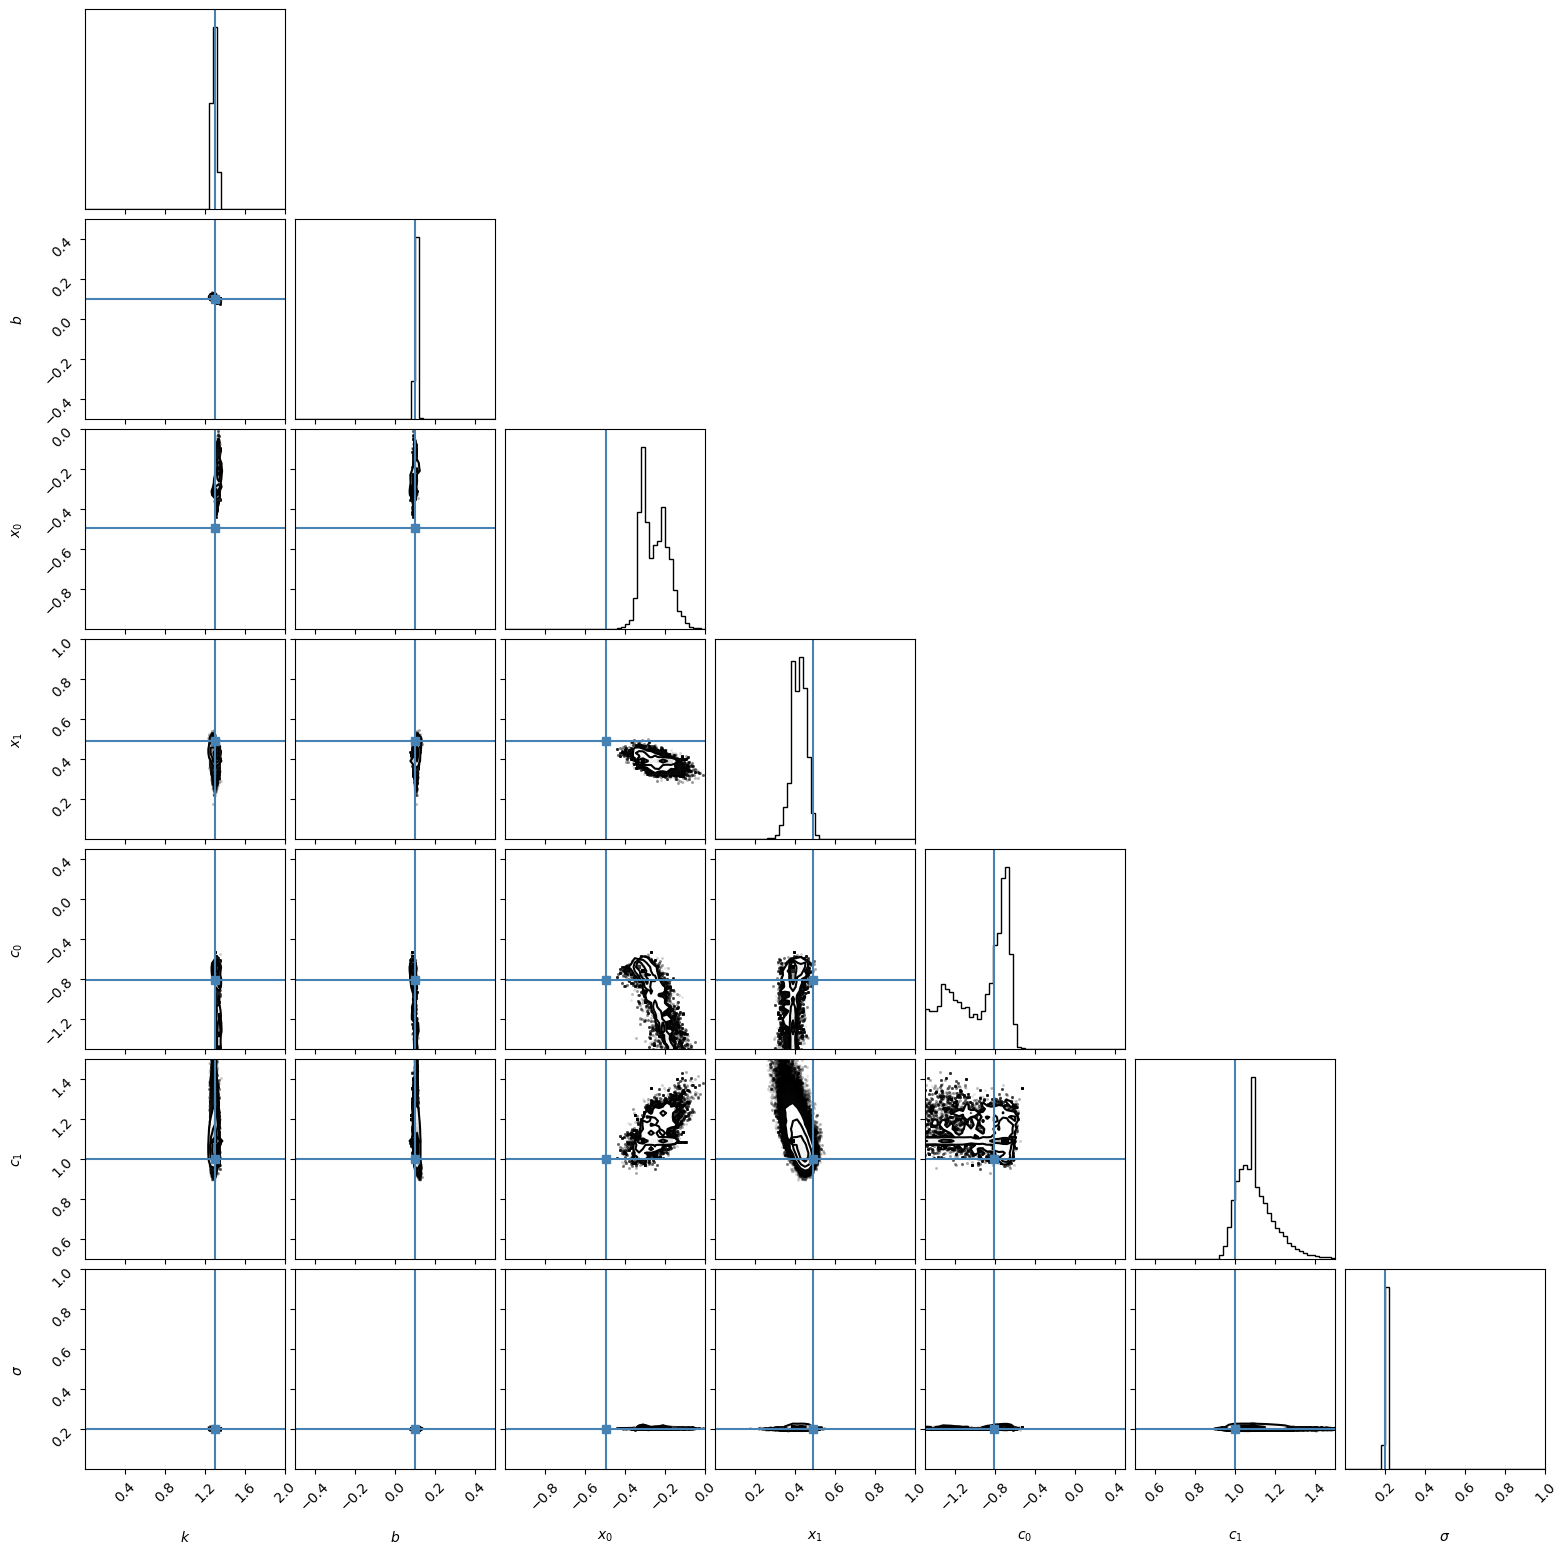

In [ ]:
fig = corner(
    sampler.get_chain(flat=True, discard=5000),
    truths=[k, b, x0, x1, c0, c1, sig],
    labels=["$k$", "$b$", "$x_0$", "$x_1$", "$c_0$", "$c_1$", "$\sigma$"],
    range=[(0, 2), (-0.5, 0.5), (-1, 0), (0, 1), (-1.5, 0.5), (0.5, 1.5),
           (0, 1)],
    bins=50,
    # plot_datapoints=False,
    plot_density=True,
)

## Compare

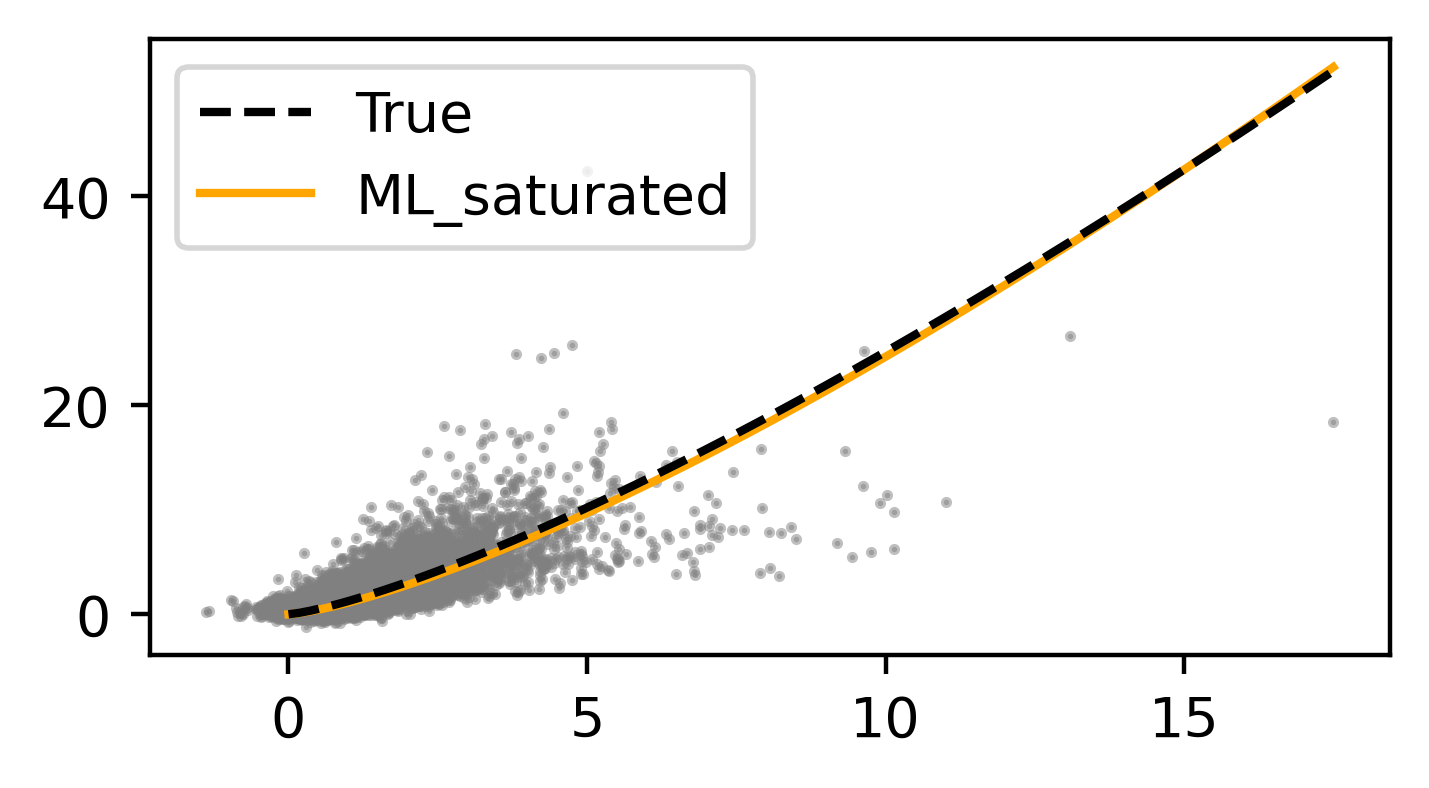

In [ ]:
plt.figure(figsize=(4, 2), dpi=400)

plt.scatter(x_obs, y_obs, s=1, color='gray', alpha=0.5)
xx = np.linspace(max(1e-10, x_obs.min()), x_obs.max(), 100)
yy = 10**(k * np.log10(xx) + b)
yy_ML = 10**(params_ml[0] * np.log10(xx) + params_ml[1])
yy_MLT = 10**(params_ml_t[0] * np.log10(xx) + params_ml_t[1])
yy_KS = 10**(params_mean[0] * np.log10(xx) + params_mean[1])
# yy_ML_saturated = 10**saturated_linear_smooth(np.log10(xx),
#                                               *params_ml_saturated_c[:-1])
yy_ML_saturated = 10**(params_ml_saturated_c[0] * np.log10(xx) +
                       params_ml_saturated_c[1])

plt.plot(xx, yy, color='black', label='True', zorder=10, linestyle='--')
plt.plot(xx, yy_ML, color='green', label='ML')
plt.plot(xx, yy_MLT, color='red', label='MLT')
plt.plot(xx, yy_KS, color='blue', label='KS')
plt.plot(xx, yy_ML_saturated, color='orange', label='ML_saturated')

plt.legend()